# Celulosa y madera uruguaya: a dónde van y qué tan expuestas están

Agustín Costa · noviembre 2026

En mi tesis de maestría trabajé la relación entre certificación forestal, la regulación europea de deforestación (EUDR) y la competitividad del sector forestal exportador. Una de las preguntas que quedó abierta fue cuánto pesa realmente Europa hoy como destino y qué tan rápido se está moviendo esa geografía. Acá la retomo con datos de UN Comtrade para 2015–2025.

Tres preguntas guían el análisis:

- ¿Las estadísticas aduaneras de Uruguay alcanzan para medir el complejo forestal?
- ¿Cómo cambió el reparto de la celulosa entre la Unión Europea, China y Estados Unidos?
- ¿Qué tan concentrados están los compradores?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt

pd.options.display.float_format = '{:,.1f}'.format
COL = {'UE27': '#2a78d6', 'China': '#eb6834', 'Estados Unidos': '#1baf7a', 'Resto': '#b5b3ad'}
INK, MUTED = '#1f1f1e', '#6b6a66'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.spines.left': False, 'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': '#e6e5e1',
                     'grid.linewidth': .6, 'axes.axisbelow': True, 'axes.edgecolor': '#8a8984',
                     'font.size': 10, 'text.color': INK, 'axes.labelcolor': INK})

def titulo(ax, t, sub):
    ax.text(0, 1.13, t, transform=ax.transAxes, fontsize=12.5, weight='bold', color=INK)
    ax.text(0, 1.05, sub, transform=ax.transAxes, fontsize=9.5, color=MUTED)

expo = pd.read_csv('uy_exportaciones_cap44_comtrade.csv', dtype={'hs': str})
espejo = pd.read_csv('espejo_celulosa_4703_comtrade.csv')

## Los datos

Uso dos consultas a la API pública de Comtrade (el script está en `descarga_comtrade.py`):

- **Lo que Uruguay declara exportar**: capítulo 44 (madera), rolos (4403) y madera aserrada (4407). Guardo el total mundial, los 15 principales destinos de cada año y el resto agrupado.
- **Lo que los demás países declaran importar desde Uruguay** en celulosa química (4703). Son los llamados datos espejo. Están valuados CIF, así que incluyen flete y seguro.

Antes de analizar, verifico que los destinos sumen el total y cuántos países reportaron cada año.

In [2]:
chk = (expo[expo.socio_cod != 0].groupby(['anio', 'hs']).valor_usd.sum()
       .div(expo[expo.socio_cod == 0].set_index(['anio', 'hs']).valor_usd) - 1)
print(f'Diferencia máxima entre suma de destinos y total mundial: {chk.abs().max():.4%}')
espejo[espejo.importador_cod != 858].groupby('anio').importador.nunique().rename('países informantes').to_frame().T

Diferencia máxima entre suma de destinos y total mundial: 0.0000%


anio,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
países informantes,26,33,36,33,36,34,39,42,48,50,46


Las sumas cierran. Ojo con 2025: reportaron 46 países contra 50 en 2024, así que tomo ese año como preliminar y me apoyo más en las participaciones que en los niveles.

## Primero, un problema de medición

Si uno busca la celulosa en lo que Uruguay informa a Comtrade, prácticamente no la encuentra. La razón es que las plantas están en zonas francas y lo que sale de ellas al exterior queda fuera de la estadística aduanera del país. Lo que sí aparece es la madera que entra a esas plantas, registrada como "exportación" con destino zona franca.

In [3]:
rolos = expo[expo.hs == '4403'].pivot_table(index='anio', columns='socio_cod', values='valor_usd')
zf = rolos[838] / rolos[0] * 100
cel_uy_2022 = 310_839   # HS 4703 informado por Uruguay en 2022 (consulta directa a la API)
cel_espejo_2022 = espejo[(espejo.anio == 2022) & (espejo.importador_cod != 858)].valor_usd.sum()
print(f'Rolos con destino zona franca: entre {zf.min():.0f}% y {zf.max():.0f}% del valor, según el año')
print(f'Celulosa 2022 según Uruguay:          USD {cel_uy_2022/1e6:>8,.1f} millones')
print(f'Celulosa 2022 según los compradores:  USD {cel_espejo_2022/1e6:>8,.1f} millones')

Rolos con destino zona franca: entre 67% y 96% del valor, según el año
Celulosa 2022 según Uruguay:          USD      0.3 millones
Celulosa 2022 según los compradores:  USD  2,274.2 millones


La diferencia es de más de 7.000 veces. Cualquier análisis del complejo forestal que use solo la estadística aduanera nacional deja afuera su principal producto. Por eso, para la celulosa, trabajo con los datos espejo.

## Europa deja de ser mayoría

In [4]:
e = espejo[espejo.importador_cod != 858].copy()   # excluyo reimportaciones
e['grupo'] = 'Resto'
e.loc[e.ue27, 'grupo'] = 'UE27'
e.loc[e.importador_cod == 156, 'grupo'] = 'China'
e.loc[e.importador_cod == 842, 'grupo'] = 'Estados Unidos'
orden = ['UE27', 'China', 'Estados Unidos', 'Resto']
p = e.pivot_table(index='anio', columns='grupo', values='valor_usd', aggfunc='sum').reindex(columns=orden).fillna(0)
part = p.div(p.sum(axis=1), axis=0) * 100
pd.concat({'USD millones': (p / 1e6).round(0), 'Participación %': part.round(1)}, axis=1)

USD millones                              Participación %        \
grupo         UE27   China Estados Unidos Resto            UE27 China   
anio                                                                    
2015         496.0   548.0            0.0 173.0            40.8  45.0   
2016         700.0   456.0            0.0 158.0            53.3  34.7   
2017         821.0   578.0            0.0 216.0            50.8  35.8   
2018       1,139.0   625.0            0.0 259.0            56.3  30.9   
2019         974.0   533.0            0.0 250.0            55.4  30.4   
2020         720.0   427.0            0.0 209.0            53.1  31.5   
2021         924.0   546.0           26.0 293.0            51.7  30.5   
2022       1,284.0   561.0           66.0 363.0            56.4  24.7   
2023         838.0   783.0           95.0 354.0            40.5  37.8   
2024       1,087.0 1,058.0          194.0 495.0            38.4  37.3   
2025         811.0   990.0          225.0 519.0            31.9  38.9   

                            
grupo Estados Unidos Resto  
anio                        
2015             0.0  14.2  
2016             0.0  12.0  
2017             0.0  13.4  
2018             0.0  12.8  
2019             0.0  14.2  
2020             0.0  15.4  
2021             1.5  16.4  
2022             2.9  16.0  
2023             4.6  17.1  
2024             6.9  17.5  
2025             8.8  20.4

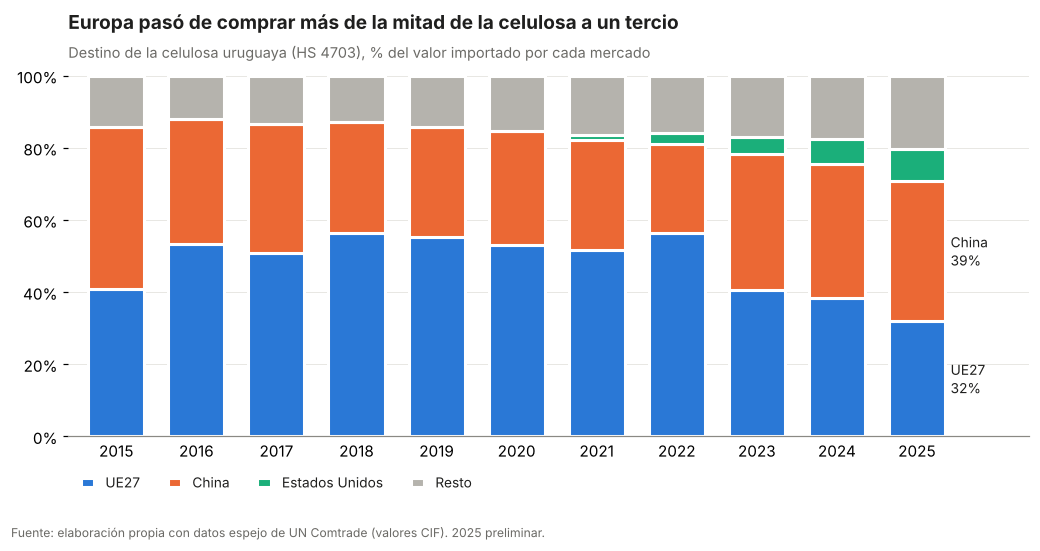

In [5]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
abajo = pd.Series(0.0, index=part.index)
for g in orden:
    ax.bar(part.index, part[g], bottom=abajo, color=COL[g], width=.7, edgecolor='white', linewidth=2, label=g)
    abajo += part[g]
for g, y in [('UE27', part.loc[2025, 'UE27'] / 2), ('China', part.loc[2025, 'UE27'] + part.loc[2025, 'China'] / 2)]:
    ax.text(2025.42, y, f'{g}\n{part.loc[2025, g]:.0f}%', va='center', fontsize=9, color=INK, linespacing=1.1)
ax.set_xticks(part.index); ax.yaxis.set_major_formatter(mt.PercentFormatter(decimals=0))
ax.set_ylim(0, 100); ax.set_xlim(2014.4, 2026.4); ax.tick_params(axis='x', length=0)
titulo(ax, 'Europa pasó de comprar más de la mitad de la celulosa a un tercio',
       'Destino de la celulosa uruguaya (HS 4703), % del valor importado por cada mercado')
ax.legend(ncol=4, frameon=False, loc='upper left', bbox_to_anchor=(0, -.07), handlelength=1, fontsize=9)
fig.text(.01, -.04, 'Fuente: elaboración propia con datos espejo de UN Comtrade (valores CIF). 2025 preliminar.', fontsize=8, color=MUTED)
plt.tight_layout(); plt.savefig('celulosa_destinos.png', bbox_inches='tight', dpi=200); plt.show()

Entre 2016 y 2022 la Unión Europea absorbió entre 52 % y 56 % del valor. En 2023 el reparto se dio vuelta: China recuperó el primer lugar y en 2025 la UE quedó en torno al 32 %. Estados Unidos, que casi no compraba celulosa uruguaya, ya explica cerca del 9 %.

Los números son consistentes con el informe anual 2025 de Uruguay XXI, que ubica a la UE en ≈30 % y a China en ≈46 %. La brecha en China tiene tres explicaciones probables: la valuación CIF contra FOB, los países que todavía no reportaron 2025 y la celulosa que entra a Europa por puertos de tránsito (Países Bajos, Bélgica) antes de su destino final.

Que Europa pierda participación no la vuelve secundaria. Sigue comprando entre 800 y 1.100 millones de dólares por año, así que la adecuación a la EUDR mantiene su peso como condición de acceso. Lo que cambia es el riesgo: hay menos dependencia de un único marco regulatorio y más dependencia de un único comprador.

## ¿Más diversificado o más concentrado?

Para medirlo uso el índice de Herfindahl-Hirschman (IHH), que suma el cuadrado de la participación de cada destino. Por debajo de 1.500 se considera diversificado y por encima de 2.500, muy concentrado. En celulosa cuento cada país europeo por separado, porque cada uno compra por su cuenta.

In [6]:
ihh = lambda s: ((s / s.sum() * 100) ** 2).sum()
ihh_cel = e.groupby('anio').valor_usd.apply(ihh)
ase = expo[(expo.hs == '4407') & (~expo.socio_cod.isin([0, -1]))]
ihh_ase = ase.groupby('anio').valor_usd.apply(ihh)        # aproximado: 15 principales destinos
total_ase_25 = expo.query("hs == '4407' and socio_cod == 0 and anio == 2025").valor_usd.iloc[0]
print('Madera aserrada, principales destinos 2025:')
print((ase[ase.anio == 2025].nlargest(4, 'valor_usd').set_index('socio').valor_usd / total_ase_25 * 100).round(1).to_string())

Madera aserrada, principales destinos 2025:
socio
Estados Unidos   30.3
China            16.9
Vietnam           7.9
Países Bajos      4.6


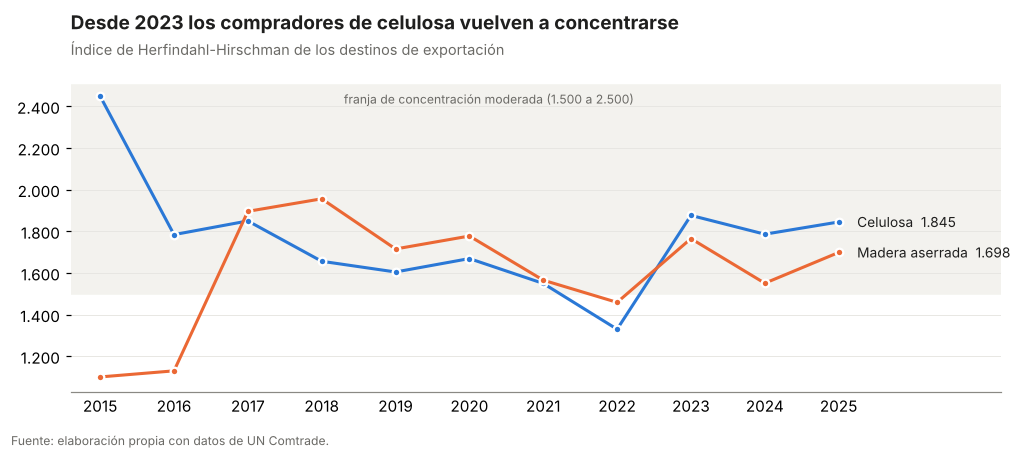

In [7]:
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.axhspan(1500, 2500, color='#f3f2ee', zorder=0)
ax.text(2018.3, 2470, 'franja de concentración moderada (1.500 a 2.500)', fontsize=8, color=MUTED, va='top')
for s, c, n in [(ihh_cel, '#2a78d6', 'Celulosa'), (ihh_ase, '#eb6834', 'Madera aserrada')]:
    ax.plot(s.index, s, color=c, lw=2, marker='o', ms=5, mec='white', mew=1.5)
    ax.text(2025.25, s.iloc[-1], f'{n}  {s.iloc[-1]:,.0f}'.replace(',', '.'), va='center', fontsize=9, color=INK)
ax.set_xticks(ihh_cel.index); ax.set_xlim(2014.6, 2027.2); ax.tick_params(axis='x', length=0)
ax.yaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: f'{v:,.0f}'.replace(',', '.')))
titulo(ax, 'Desde 2023 los compradores de celulosa vuelven a concentrarse',
       'Índice de Herfindahl-Hirschman de los destinos de exportación')
fig.text(.01, -.03, 'Fuente: elaboración propia con datos de UN Comtrade.', fontsize=8, color=MUTED)
plt.tight_layout(); plt.savefig('ihh_destinos.png', bbox_inches='tight', dpi=200); plt.show()

En celulosa, la concentración cayó hasta 2022, cuando el negocio se repartía entre Europa y China, y volvió a subir con el regreso de China al primer lugar. La madera aserrada se mueve en niveles parecidos y depende sobre todo de Estados Unidos (30 % del valor en 2025), seguido por China y Vietnam.

## Conclusiones

- **Medición.** El complejo forestal no se puede leer solo con la estadística aduanera nacional. Hacen falta los datos de zonas francas o los datos espejo.
- **Mercados.** La UE dejó de ser el destino mayoritario de la celulosa, pero sigue siendo grande. China volvió al primer lugar y Estados Unidos ganó peso tanto en celulosa como en madera aserrada.
- **Riesgo.** La exposición a la EUDR sigue siendo alta en valor y la dependencia de China crece. La concentración de destinos es un indicador que conviene seguir año a año.

**Límites y próximos pasos.** Los datos espejo están en CIF y 2025 es preliminar. El IHH de madera aserrada es aproximado. El paso natural siguiente es comparar precios unitarios (USD/t) por destino para ver si Europa paga una prima, que era la pregunta central de mi tesis.